# Lab notebook — data ingestion and first analysis (HW9)

PHYS 7440, final project *Reproducing the atmospheric-neutrino anomaly from public data, with and without AI*. Author: Andrea Aguilar-Mayorga.

This notebook records, in order:
1. **Raw output of a real API call** (HEPData, Super-K ν_e spectrum), checked against its registered SHA-256.
2. **The normalized version** of that output, in the internal schema of `data_pipeline_aguilar_mayorga.py`, and the SQLite cache of all three datasets.
3. **The first analysis result**: the double ratio R computed by code only (layer C).
4. **AI vs. baseline plot** on 5 requests: the model without tools (A₀, the baseline designed in week 8) against the code reference R_C.

Layers: **P** = published values (never shown to any AI system, not used here); **C** = this code, no AI at run time; **A₀** = `claude-opus-5-5` without tools or data; **A** = the agent with MCP tools (not implemented yet).

Run it from the `atm_nu_double_ratio` folder after `make pipeline`.

In [1]:
import json
import sqlite3
import sys
import tempfile
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np

PROJECT = Path.cwd()
sys.path.insert(0, str(PROJECT / "src"))

from atmflux import data_pipeline_aguilar_mayorga as dp

registry = {r["file"]: r for r in json.loads((PROJECT / "data/provenance.json").read_text())}

## 1. Raw output of one API call

A real HTTP request to HEPData through `dp.fetch` (curl as transport, `tenacity` retries with exponential backoff). If the network is down, the cell says so and shows the raw cache instead; it never invents data.

In [2]:
rec = registry["sk_nue_flux.csv"]
url = rec["source"]
try:
    raw = dp.fetch(url)
    origin = f"Downloaded now from {url}"
except Exception as exc:
    raw = (PROJECT / "data" / rec["file"]).read_bytes()
    origin = f"Download failed ({type(exc).__name__}: {exc}); showing the raw cache data/{rec['file']}"
print(origin)
print("Bytes:", len(raw), "| SHA-256 matches the registry:", dp.sha256_bytes(raw) == rec["sha256"])
print("-" * 80)
print(raw.decode())

Downloaded now from https://www.hepdata.net/download/table/ins1401192/Table%201/1/csv
Bytes: 942 | SHA-256 matches the registry: True
--------------------------------------------------------------------------------
#: table_doi: 10.17182/hepdata.76912.v1/t1
#: name: Table 1
#: description: Electron neutrino flux measured by SK I-IV data.  Error written in percentage including both statistical and systematic uncertainties.

#: data_file: Table1.yaml
#: keyword reactions: NUE NUCLEON --> E- X
#: keyword observables: FLUX
#: keyword phrases: Inclusive | Electron Production | Charged Current | Deep Inelastic Scattering
$\log_{10}(E/\rm{GeV})$,$\log_{10}(E/\rm{GeV})$ LOW,$\log_{10}(E/\rm{GeV})$ HIGH,$\bar{E}^2\Phi^{\nu}$ [GeV/cm$^{2}$/sec/sr],error +,error -
-0.71,-0.8,-0.6,0.0121,18.0%,-18.0%
-0.51,-0.6,-0.4,0.0146,17.0%,-17.0%
-0.27,-0.4,-0.2,0.015,16.0%,-16.0%
-0.09,-0.2,0.0,0.0137,15.0%,-15.0%
0.1,0.0,0.2,0.0116,17.0%,-17.0%
0.30000000000000004,0.2,0.4,0.00855,17.0%,-17.0%
0.5,0.4,0.6,0

## 2. Normalized version

Same bytes, after `normalize_hepdata`: bin edges in GeV, the error converted from percent to absolute, and the common unit GeV cm⁻² s⁻¹ sr⁻¹. A missing field would appear as `nan` with its name in `missing` (sentinel; never 0).

In [3]:
rows = dp.normalize_hepdata(raw, "sk_nue", url)
print(f"{'flavor':12s} {'E_lo [GeV]':>10s} {'E_hi [GeV]':>10s} {'E2Phi':>11s} {'error':>11s}  unit                  missing")
for r in rows:
    print(f"{r['flavor']:12s} {r['e_lo_gev']:10.4g} {r['e_hi_gev']:10.4g} {r['value']:11.4e} "
          f"{r['error']:11.4e}  {r['unit']}  {r['missing'] or '-'}")

flavor       E_lo [GeV] E_hi [GeV]       E2Phi       error  unit                  missing
nue+nuebar       0.1585     0.2512  1.2100e-02  2.1780e-03  GeV cm^-2 s^-1 sr^-1  -
nue+nuebar       0.2512     0.3981  1.4600e-02  2.4820e-03  GeV cm^-2 s^-1 sr^-1  -
nue+nuebar       0.3981      0.631  1.5000e-02  2.4000e-03  GeV cm^-2 s^-1 sr^-1  -
nue+nuebar        0.631          1  1.3700e-02  2.0550e-03  GeV cm^-2 s^-1 sr^-1  -
nue+nuebar            1      1.585  1.1600e-02  1.9720e-03  GeV cm^-2 s^-1 sr^-1  -
nue+nuebar        1.585      2.512  8.5500e-03  1.4535e-03  GeV cm^-2 s^-1 sr^-1  -
nue+nuebar        2.512      3.981  6.0900e-03  1.0962e-03  GeV cm^-2 s^-1 sr^-1  -
nue+nuebar        3.981       6.31  3.7300e-03  7.0870e-04  GeV cm^-2 s^-1 sr^-1  -
nue+nuebar         6.31         10  2.3200e-03  4.1760e-04  GeV cm^-2 s^-1 sr^-1  -
nue+nuebar           10      31.62  9.4200e-04  1.4130e-04  GeV cm^-2 s^-1 sr^-1  -
nue+nuebar        31.62        100  2.0300e-04  3.6540e-05  GeV cm^-2 

### The SQLite cache (all three datasets)

Written by `make pipeline`. The provenance record of the last run is `provenance_aguilar_mayorga.json`.

In [4]:
prov = json.loads((PROJECT / "provenance_aguilar_mayorga.json").read_text())
print("Provenance generated:", prov["generated_utc"], "| code:", prov["code_version"])
for d in prov["datasets"]:
    print(f"  {d['dataset']:8s} {d['access']['status']:28s} {d['source_url']}")

con = sqlite3.connect(PROJECT / "data/cache/atmflux_cache.sqlite")
print()
print("dataset   flavor          kind   rows  unit")
for row in con.execute("SELECT dataset, flavor, kind, COUNT(*), unit FROM measurements "
                       "GROUP BY dataset, flavor ORDER BY dataset, flavor"):
    print("{:9s} {:15s} {:6s} {:5d}  {}".format(*row))
print("\nRows with a missing field:", con.execute("SELECT COUNT(*) FROM measurements WHERE missing != ''").fetchone()[0])

Provenance generated: 2026-11-26T00:09:56+00:00 | code: {'commit': 'be50e122621c2317b2f4b9cb7ee3cbc1e11bc33c', 'uncommitted_changes_in_project': True}
  sk_numu  downloaded                   https://www.hepdata.net/download/table/ins1401192/Table%202/1/csv
  sk_nue   downloaded                   https://www.hepdata.net/download/table/ins1401192/Table%201/1/csv
  honda    downloaded                   http://www-rccn.icrr.u-tokyo.ac.jp/mhonda/public/nflx2014/kam-ally-20-01-solmin.d.gz

dataset   flavor          kind   rows  unit
honda     nue             point   2020  GeV cm^-2 s^-1 sr^-1
honda     nuebar          point   2020  GeV cm^-2 s^-1 sr^-1
honda     numu            point   2020  GeV cm^-2 s^-1 sr^-1
honda     numubar         point   2020  GeV cm^-2 s^-1 sr^-1
sk_nue    nue+nuebar      bin       11  GeV cm^-2 s^-1 sr^-1
sk_numu   numu+numubar    bin       12  GeV cm^-2 s^-1 sr^-1

Rows with a missing field: 0


Both sources now share one unit, so they can be overlaid directly. Below, the Honda prediction is angle-averaged from the cache (weights |Δcos θ|/2, ν + ν̄ summed) and drawn with the Super-K spectra. The ν_μ deficit below a few tens of GeV is the oscillation signal (upward-going ν_μ have travelled far enough to oscillate); ν_e agree with the prediction.

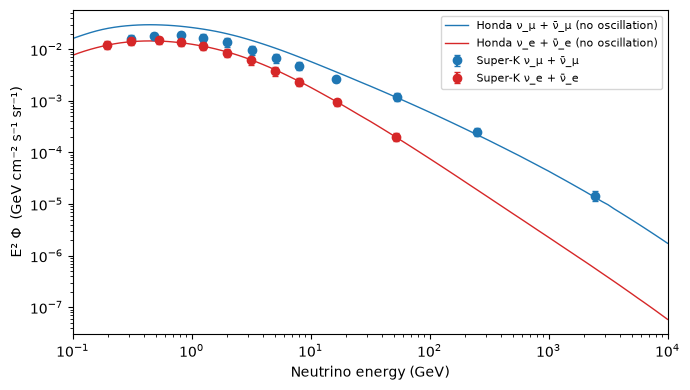

In [5]:
def honda_from_cache(flavors):
    q = ("SELECT e_gev, SUM(value * (cosz_max - cosz_min) / 2) FROM measurements "
         f"WHERE dataset='honda' AND flavor IN ({','.join('?' * len(flavors))}) GROUP BY e_gev ORDER BY e_gev")
    e, v = np.array(con.execute(q, flavors).fetchall()).T
    return e, v

fig, ax = plt.subplots(figsize=(7, 4))
for ds, flavors, color, label in [("sk_numu", ["numu", "numubar"], "C0", "ν_μ + ν̄_μ"),
                                  ("sk_nue", ["nue", "nuebar"], "C3", "ν_e + ν̄_e")]:
    sk = con.execute("SELECT e_gev, value, error FROM measurements WHERE dataset=? ORDER BY e_gev", (ds,)).fetchall()
    e, v, err = np.array(sk).T
    ax.errorbar(e, v, yerr=err, fmt="o", color=color, capsize=2, label=f"Super-K {label}")
    he, hv = honda_from_cache(flavors)
    ax.plot(he, hv, color=color, lw=1, label=f"Honda {label} (no oscillation)")
ax.set(xscale="log", yscale="log", xlabel="Neutrino energy (GeV)",
       ylabel="E² Φ  (GeV cm⁻² s⁻¹ sr⁻¹)", xlim=(0.1, 1e4))
ax.legend(fontsize=8)
fig.tight_layout()

## 3. First analysis result: R from code only (layer C)

`atmflux.reproduce.run` is the same pipeline as `make reproduce` (here writing to a temporary folder so the committed results are not touched).

In [6]:
from atmflux.reproduce import run as reproduce_run

results = reproduce_run(out_dir=Path(tempfile.mkdtemp()), figure=False)
print(f"{'sample':10s} {'weighting':9s} {'R_C':>6s} {'err (none)':>11s} {'err (full)':>11s}")
for sample, d in results["samples"].items():
    for w in ["sigma", "flux"]:
        x = d[w]
        print(f"{sample:10s} {w:9s} {x['R']:6.3f} {x['error_none']['R']:11.3f} {x['error_full']['R']:11.3f}")

sample     weighting    R_C  err (none)  err (full)
sub-GeV    sigma      0.595       0.069       0.141
sub-GeV    flux       0.572       0.080       0.141
multi-GeV  sigma      0.701       0.077       0.172
multi-GeV  flux       0.695       0.092       0.172


## 4. AI (A₀, no tools) vs. code reference, 5 requests

`make baseline` sends each of 5 templated requests 3 times to `claude-opus-5-5` (effort `medium`, adaptive thinking with summarized display) with **no tools and no data**, and stores every answer, its thinking summary and its final JSON in `results/a0_baseline.json`. The pass band is the project criterion |R_A − R_C| / R_C ≤ 2 %.

A₀ can only recall or estimate the inputs, so it is the floor that the agent with tools (A) must beat.

In [7]:
a0_path = PROJECT / "results/a0_baseline.json"
if not a0_path.exists():
    print("results/a0_baseline.json not found: run `make baseline` (needs ANTHROPIC_API_KEY), then re-run this notebook.")
else:
    a0 = json.loads(a0_path.read_text())
    reqs = a0["requests"]
    fig, ax = plt.subplots(figsize=(7, 4))
    x = np.arange(len(reqs))
    r_c = np.array([q["R_C"] for q in reqs])
    ax.bar(x, 2 * 0.02 * r_c, bottom=0.98 * r_c, width=0.5, color="0.85", label="±2 % of R_C (pass band)")
    ax.scatter(x, r_c, marker="_", s=600, color="k", label="R_C (code, layer C)")
    for i, q in enumerate(reqs):
        vals = [r["R_A0"] for r in q["runs"] if r["R_A0"] is not None]
        ax.scatter(np.full(len(vals), i) + np.linspace(-0.12, 0.12, len(vals)), vals,
                   color="C1", zorder=3, label="A₀ (model, no tools)" if i == 0 else None)
    ax.set_xticks(x, [q["id"] for q in reqs])
    ax.set_ylabel("R = (μ/e)_data / (μ/e)_pred")
    ax.set_title(f"A₀ = {a0['model']}, effort {a0['effort']}, {a0['runs_per_request']} runs per request", fontsize=9)
    ax.legend(fontsize=8)
    fig.tight_layout()

    n_pass = n_total = 0
    print(f"{'request':12s} {'R_C':>6s}  A0 runs (rel. diff)")
    for q in reqs:
        parts = []
        for r in q["runs"]:
            n_total += 1
            if r["R_A0"] is None:
                parts.append(f"unparsed: {r['parse_error']}")
            else:
                ok = r["rel_diff"] <= 0.02
                n_pass += ok
                parts.append(f"{r['R_A0']:.3f} ({100 * r['rel_diff']:.1f}%{' pass' if ok else ''})")
        print(f"{q['id']:12s} {q['R_C']:6.3f}  " + ", ".join(parts))
    print(f"\nWithin 2 %: {n_pass}/{n_total}")

request         R_C  A0 runs (rel. diff)
sub_sigma     0.595  0.690 (15.9%), 0.940 (57.9%), 1.000 (68.0%)
multi_sigma   0.701  0.940 (34.1%), 0.960 (36.9%), 0.720 (2.7%)
sub_flux      0.572  0.924 (61.6%), 0.950 (66.1%), 0.870 (52.1%)
multi_flux    0.695  0.940 (35.2%), 0.950 (36.6%), 0.890 (28.0%)
full_sigma    0.631  0.970 (53.8%), 0.930 (47.4%), 0.920 (45.8%)

Within 2 %: 0/15


## Observations

- **Ingestion.** All three inputs were downloaded from their original sources on 2026-11-25 and are byte-identical (SHA-256) to the copies registered on 2026-10-13. HEPData's Cloudflare front end returns HTTP 403 to Python's `urllib`, so the pipeline uses the system `curl` as transport (with its own user agent); retries, integrity checks and the cache are unchanged.
- **Normalization.** The cache reproduces exactly the arrays that layer C reads (`test_cache_matches_the_readers_used_by_layer_c`), so C and the future MCP server see the same numbers. No field is missing in the current data; the sentinel path is covered by tests.
- **A₀ baseline.** Results summarized in the README section 'A₀ baseline'; my (the author's) interpretation is pending.